In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1153.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1465.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1166.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1975.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1263.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1629.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1701.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1273.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear/thick_smear_clean/Thick_Uninfected/Image1901.jpg
/kaggle/input/datasets/matthewsenahey/thick-blood-smear

In [2]:
#Cell 1

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from PIL import Image

BASE = '/kaggle/input/datasets/matthewsenahey/thick-blood-smear'

for root, dirs, files in os.walk(BASE):
    level = root.replace(BASE, '').count(os.sep)
    if level < 3:
        indent = ' ' * 2 * level
        folder = os.path.basename(root)
        imgs = len([f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        print(f'{indent}{folder}/ — {imgs} images')

2026-07-10 23:10:12.994678: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783725013.210106      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783725013.278377      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1783725013.819249      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783725013.819308      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1783725013.819311      22 computation_placer.cc:177] computation placer alr

thick-blood-smear/ — 0 images
  thick_smear_clean/ — 0 images
    Thick_Uninfected/ — 1071 images
    Thick_Infected/ — 1139 images


In [3]:
#Cell 2

IMG_SIZE = 128
BATCH_SIZE = 32

def load_images(base_path):
    images, labels = [], []
    class_map = {'Thick_Infected': 1, 'Thick_Uninfected': 0}

    for folder, label in class_map.items():
        folder_path = None
        for root, dirs, files in os.walk(base_path):
            if os.path.basename(root) == folder:
                folder_path = root
                break

        if folder_path is None:
            print(f"WARNING: Could not find {folder}")
            continue

        files = [f for f in os.listdir(folder_path)
                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        print(f"Loading {folder} — {len(files)} images...")

        for fname in files:
            img_path = os.path.join(folder_path, fname)
            try:
                # PIL handles EXIF orientation correctly for this dataset
                img = Image.open(img_path).convert('RGB')
                img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
                images.append(np.array(img, dtype=np.float32))   # keep [0, 255]
                labels.append(label)
            except Exception as e:
                print(f"  Skipping {fname}: {e}")

    return np.array(images), np.array(labels)

X, y = load_images(BASE)
print(f"\nDataset loaded:")
print(f"  Total images : {len(X)}")
print(f"  Infected     : {sum(y == 1)}")
print(f"  Uninfected   : {sum(y == 0)}")
print(f"  Image shape  : {X[0].shape}")
print(f"  Pixel range  : {X.min():.1f} — {X.max():.1f}")

Loading Thick_Infected — 1139 images...
Loading Thick_Uninfected — 1071 images...

Dataset loaded:
  Total images : 2210
  Infected     : 1139
  Uninfected   : 1071
  Image shape  : (128, 128, 3)
  Pixel range  : 0.0 — 244.0


In [4]:
#Cell 3

# 73% train / 12% val / 15% test, same methodology as the thin smear model
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1412, random_state=42, stratify=y_temp)

print(f"Train : {len(X_train)} images")
print(f"Val   : {len(X_val)} images")
print(f"Test  : {len(X_test)} images")
print(f"\nTrain class balance -- Infected: {sum(y_train == 1)}, Uninfected: {sum(y_train == 0)}")

Train : 1612 images
Val   : 266 images
Test  : 332 images

Train class balance -- Infected: 831, Uninfected: 781


In [5]:
#Cell 4

def build_thick_smear_model(input_shape=(128, 128, 3)):
    # EfficientNetB2 has internal rescaling, so inputs stay in [0, 255]
    backbone = EfficientNetB2(
        include_top=False,
        weights='imagenet',
        input_shape=input_shape
    )
    backbone.trainable = False   # freeze entirely for Phase 1

    inputs = layers.Input(shape=input_shape)
    x = backbone(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.1)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    return Model(inputs, outputs), backbone

model, backbone = build_thick_smear_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Recall(name='sensitivity'),
             tf.keras.metrics.Precision(name='precision')]
)

model.summary()
print(f"\nTotal params     : {model.count_params():,}")
print(f"Trainable params : {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")

I0000 00:00:1783725292.736643      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783725292.742415      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb2 (Functional)     │ (None, 4, 4, 1408)     │     7,768,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1408)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1408)           │         5,632 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       360,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,136,186 (31.04 MB)

 Trainable params: 364,289 (1.39 MB)

 Non-trainable params: 7,771,897 (29.65 MB)


Total params     : 8,136,186
Trainable params : 364,289


In [6]:
#Cell 5
callbacks_phase1 = [
    EarlyStopping(monitor='val_loss', patience=5,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint('/kaggle/working/thick_model_phase1.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-7, verbose=1)
]
print("Phase 1: Training classification head (backbone frozen)...")
history1 = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_phase1,
    verbose=1
)

print("=" * 60)
print("Phase 1 complete!")
print(f"  Epochs completed         : {len(history1.history['accuracy'])}")
print(f"  Best validation accuracy : {max(history1.history['val_accuracy'])*100:.2f}%")
print("=" * 60)

Phase 1: Training classification head (backbone frozen)...
Epoch 1/50


I0000 00:00:1783725311.624119      70 service.cc:152] XLA service 0x79f3cc0573d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783725311.624392      70 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1783725311.624396      70 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1783725314.882254      70 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-07-10 23:15:23.639319: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:15:23.772877: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:15:24.087870: E external/local_xl

49/51 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7520 - loss: 0.5508 - precision: 0.7602 - sensitivity: 0.7549

2026-07-10 23:15:47.287183: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:15:47.419743: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:15:47.732278: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:15:47.874565: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:15:48.663370: E external/local_xla/xla/stream_

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.7551 - loss: 0.5448 - precision: 0.7632 - sensitivity: 0.7580

2026-07-10 23:16:15.516968: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:16:15.650230: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:16:15.952303: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:16:16.094472: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:16:16.872106: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.93985, saving model to /kaggle/working/thick_model_phase1.keras

Epoch 1: finished saving model to /kaggle/working/thick_model_phase1.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 87s 937ms/step - accuracy: 0.8319 - loss: 0.3965 - precision: 0.8382 - sensitivity: 0.8351 - val_accuracy: 0.9398 - val_loss: 0.2831 - val_precision: 0.9416 - val_sensitivity: 0.9416 - learning_rate: 0.0010
Epoch 2/50
50/51 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8953 - loss: 0.2545 - precision: 0.9024 - sensitivity: 0.8934
Epoch 2: val_accuracy did not improve from 0.93985
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8995 - loss: 0.2419 - precision: 0.9084 - sensitivity: 0.8953 - val_accuracy: 0.9398 - val_loss: 0.2526 - val_precision: 0.9060 - val_sensitivity: 0.9854 - learning_rate: 0.0010
Epoch 3/50
49/51 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9078 - loss: 0.2126 - precision: 0.9233 - sensitivity: 0.8985
Epoch 3: val_accuracy did not improve from

In [7]:
#Cell 6
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
# --- Class weighting: nudge the model to prioritize catching infections ---
# Base balanced weights, then give the infected class (1) a modest extra boost
base = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: base[0], 1: base[1] * 1.15}   # 1.15x lean toward sensitivity
print(f"Class weights: {class_weight}")
# --- Unfreeze top 40 non-BatchNorm backbone layers (was 20); keep BN frozen ---
backbone.trainable = True
unfrozen = 0
for layer in reversed(backbone.layers):
    if unfrozen >= 40:
        layer.trainable = False
    elif isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True
        unfrozen += 1
print(f"Non-BN layers unfrozen: {unfrozen}")
# Lower LR for a gentler, deeper fine-tune
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Recall(name='sensitivity'),
             tf.keras.metrics.Precision(name='precision')]
)
callbacks_phase2 = [
    # Monitor sensitivity now, not accuracy — we want the checkpoint that catches most infections
    EarlyStopping(monitor='val_sensitivity', mode='max', patience=8,
                  restore_best_weights=True, verbose=1),
    ModelCheckpoint('/kaggle/working/best_thick_smear_model.keras',
                    monitor='val_sensitivity', mode='max',
                    save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=4, min_lr=1e-7, verbose=1)
]
print("Phase 2 (v2): Fine-tuning top 40 layers, class-weighted, lr=5e-5...")
history2 = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks_phase2,
    verbose=1
)

phase1_epochs = len(history1.history['accuracy'])
phase2_epochs = len(history2.history['accuracy'])
best_val_acc  = max(history1.history['val_accuracy'] + history2.history['val_accuracy']) * 100
best_val_sens = max(history2.history['val_sensitivity']) * 100

print("=" * 60)
print("Training complete!")
print(f"  Phase 1 epochs           : {phase1_epochs}")
print(f"  Phase 2 epochs           : {phase2_epochs}")
print(f"  Total epochs completed   : {phase1_epochs + phase2_epochs}")
print(f"  Best validation accuracy : {best_val_acc:.2f}%")
print(f"  Best validation sensitiv.: {best_val_sens:.2f}%")
print("=" * 60)

Class weights: {0: np.float64(1.0320102432778488), 1: np.float64(1.1154031287605295)}
Non-BN layers unfrozen: 40
Phase 2 (v2): Fine-tuning top 40 layers, class-weighted, lr=5e-5...
Epoch 1/40
50/51 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9654 - loss: 0.1060 - precision: 0.9725 - sensitivity: 0.9596

2026-07-10 23:17:37.486974: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:17:37.627305: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-07-10 23:17:37.765449: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.9655 - loss: 0.1061 - precision: 0.9724 - sensitivity: 0.9597
Epoch 1: val_sensitivity improved from None to 0.97810, saving model to /kaggle/working/best_thick_smear_model.keras

Epoch 1: finished saving model to /kaggle/working/best_thick_smear_model.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 73s 720ms/step - accuracy: 0.9665 - loss: 0.1083 - precision: 0.9675 - sensitivity: 0.9675 - val_accuracy: 0.9774 - val_loss: 0.0967 - val_precision: 0.9781 - val_sensitivity: 0.9781 - learning_rate: 5.0000e-05
Epoch 2/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9590 - loss: 0.1191 - precision: 0.9669 - sensitivity: 0.9544
Epoch 2: val_sensitivity improved from 0.97810 to 0.99270, saving model to /kaggle/working/best_thick_smear_model.keras

Epoch 2: finished saving model to /kaggle/working/best_thick_smear_model.keras
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.9665 - loss: 0.0985 - precision: 0.9686 - sensitivity: 0.9663 - val

THICK SMEAR MODEL — TEST SET EVALUATION
EfficientNetB2 — NM-AIST Tanzania Dataset
Total test images                   332
Accuracy                            95.48%
Sensitivity                         97.08% PASS (WHO >= 95%)
Specificity                         93.79% PASS (WHO >= 90%)
Precision                           94.32%
F1 Score                            95.68%


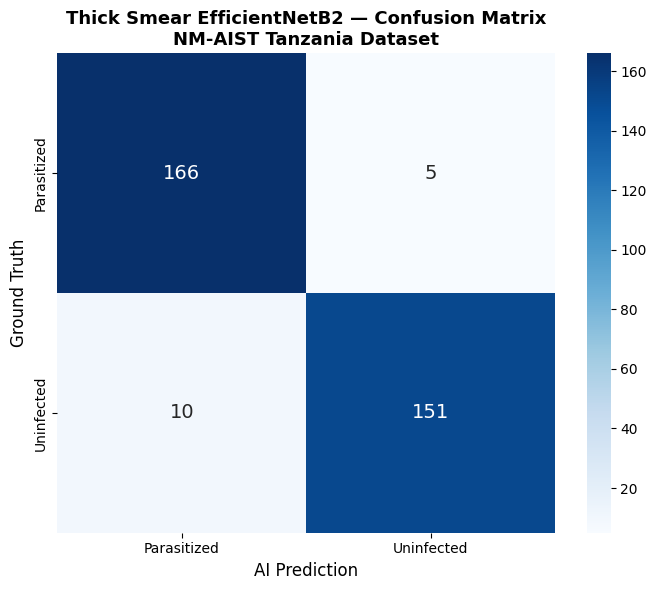

              precision    recall  f1-score   support

 Parasitized       0.94      0.97      0.96       171
  Uninfected       0.97      0.94      0.95       161

    accuracy                           0.95       332
   macro avg       0.96      0.95      0.95       332
weighted avg       0.96      0.95      0.95       332



In [8]:
#Cell 7
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import seaborn as sns

best_model = tf.keras.models.load_model('/kaggle/working/best_thick_smear_model.keras')

y_pred_prob = best_model.predict(X_test, verbose=0).flatten()
y_pred = (y_pred_prob >= 0.5).astype(int)

accuracy    = accuracy_score(y_test, y_pred) * 100
sensitivity = recall_score(y_test, y_pred, pos_label=1) * 100
specificity = recall_score(y_test, y_pred, pos_label=0) * 100
precision   = precision_score(y_test, y_pred, pos_label=1) * 100
f1          = f1_score(y_test, y_pred, pos_label=1) * 100

print("=" * 60)
print("THICK SMEAR MODEL — TEST SET EVALUATION")
print("EfficientNetB2 — NM-AIST Tanzania Dataset")
print("=" * 60)
print(f"{'Total test images':<35} {len(X_test)}")
print(f"{'Accuracy':<35} {accuracy:.2f}%")
print(f"{'Sensitivity':<35} {sensitivity:.2f}% {'PASS' if sensitivity >= 95 else 'FAIL'} (WHO >= 95%)")
print(f"{'Specificity':<35} {specificity:.2f}% {'PASS' if specificity >= 90 else 'FAIL'} (WHO >= 90%)")
print(f"{'Precision':<35} {precision:.2f}%")
print(f"{'F1 Score':<35} {f1:.2f}%")
print("=" * 60)

# labels=[1, 0] forces row/col order to Parasitized (1) then Uninfected (0)
cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Parasitized', 'Uninfected'],
            yticklabels=['Parasitized', 'Uninfected'],
            annot_kws={"size": 14})
plt.title('Thick Smear EfficientNetB2 — Confusion Matrix\nNM-AIST Tanzania Dataset',
          fontsize=13, fontweight='bold')
plt.ylabel('Ground Truth', fontsize=12)
plt.xlabel('AI Prediction', fontsize=12)
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, labels=[1, 0],
      target_names=['Parasitized', 'Uninfected']))

In [9]:
#Cell 8

import zipfile

zip_path = '/kaggle/working/thick_smear_model.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    zf.write('/kaggle/working/best_thick_smear_model.keras',
             arcname='best_thick_smear_model.keras')

size = os.path.getsize(zip_path) / (1024 * 1024)
print(f"Model saved and zipped: {zip_path}")
print(f"Zip size: {size:.2f} MB")
print("Download from the Kaggle Output panel.")

Model saved and zipped: /kaggle/working/thick_smear_model.zip
Zip size: 66.71 MB
Download from the Kaggle Output panel.


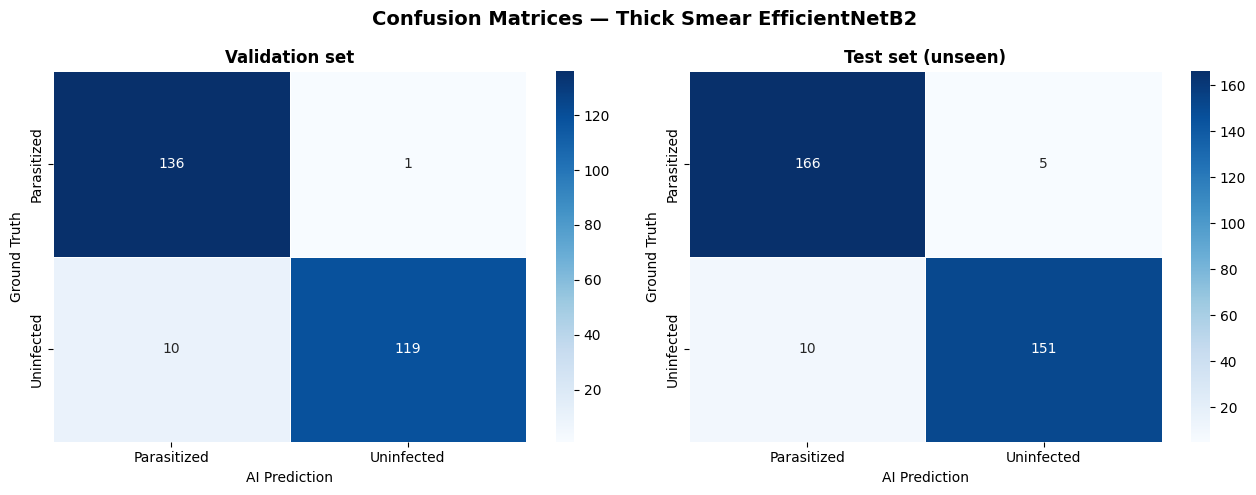

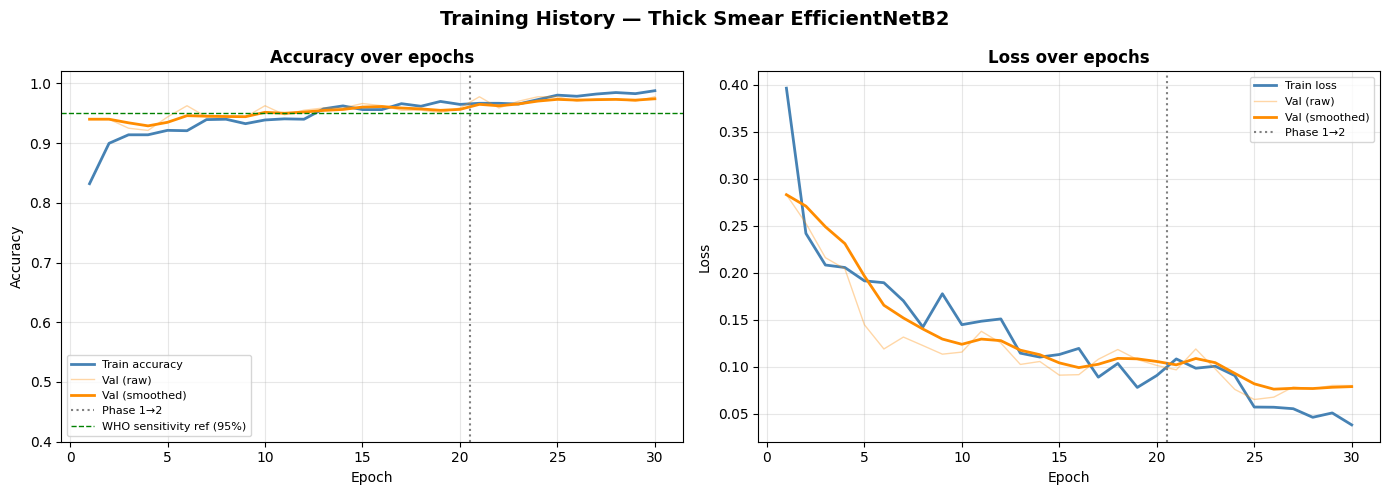

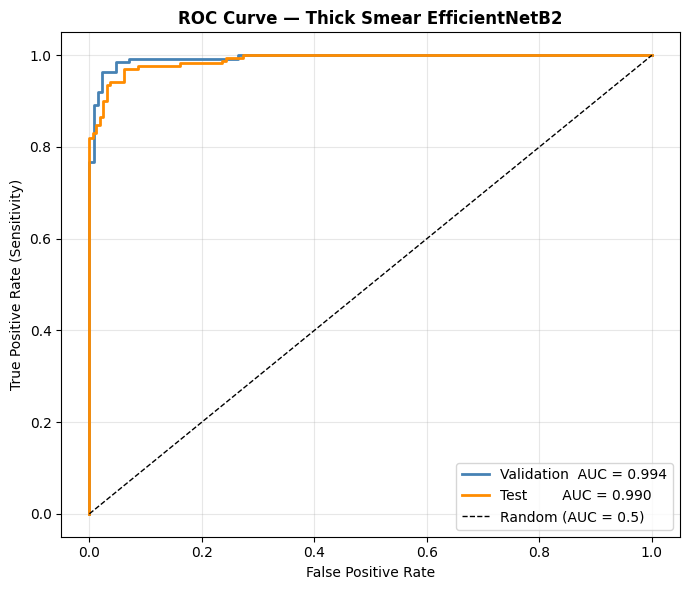

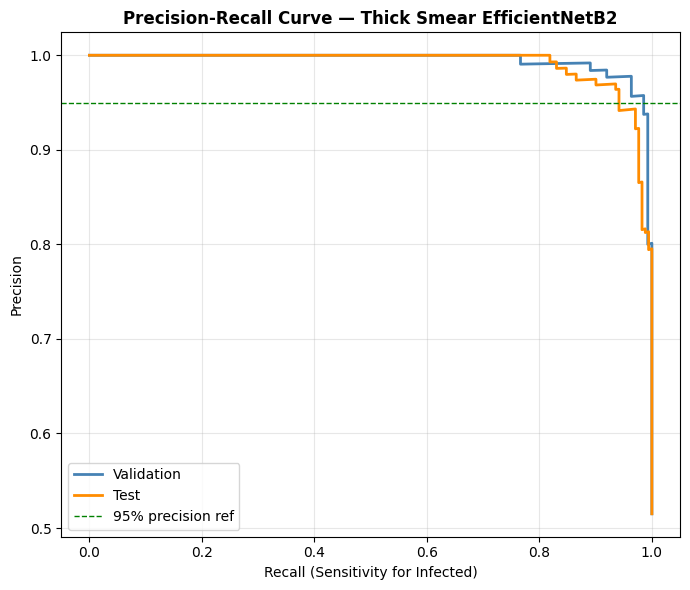

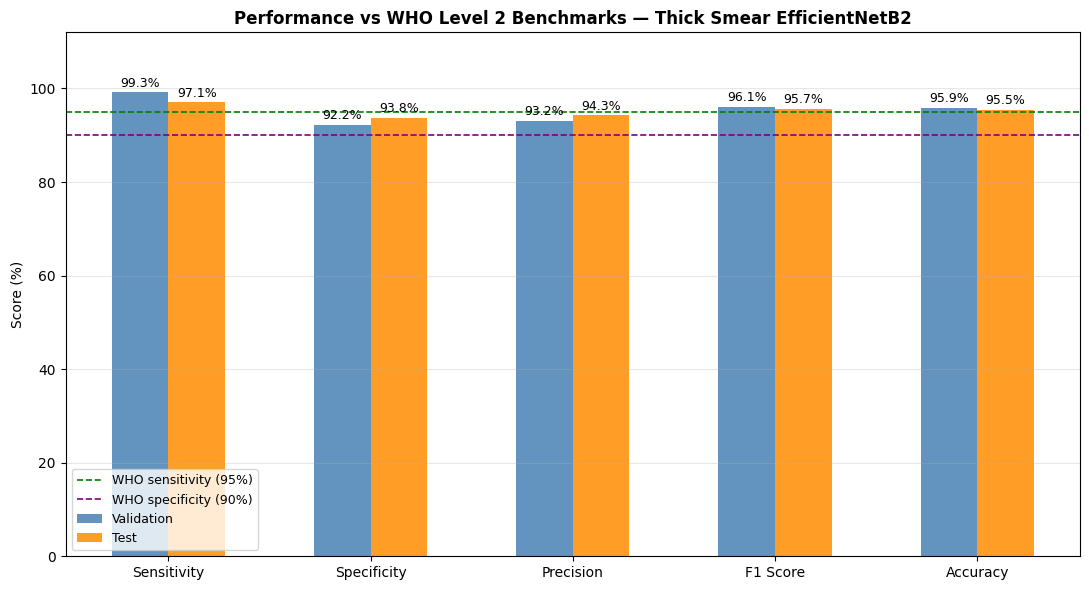

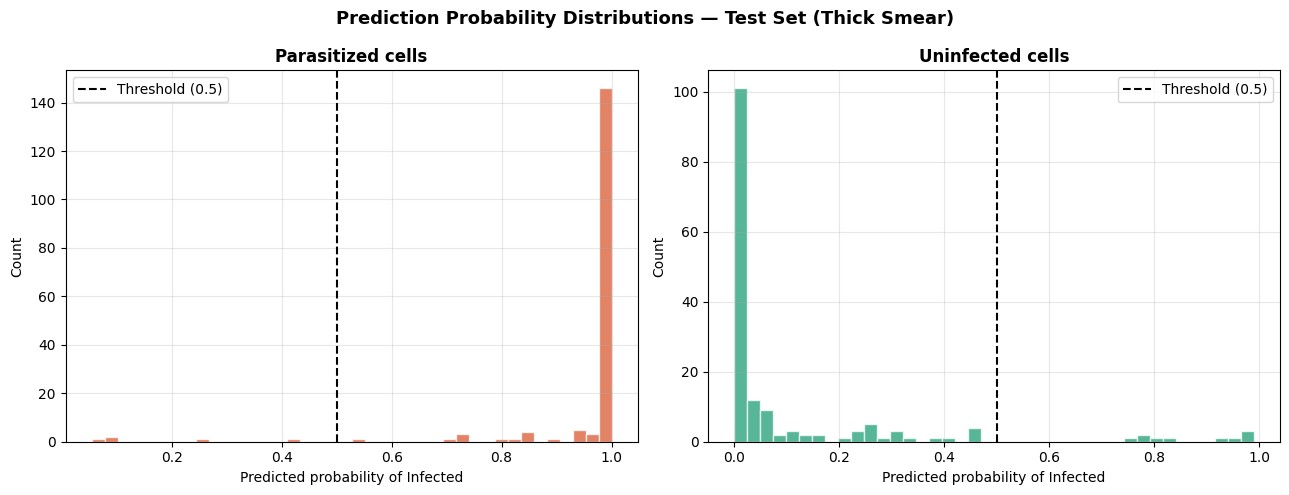

In [10]:
#Cell 9
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_curve, auc,
                             precision_recall_curve, recall_score,
                             precision_score, f1_score, accuracy_score)

# --- Predictions at natural 0.5 threshold; label 1 = Infected (positive) ---
val_prob  = best_model.predict(X_val,  verbose=0).flatten()
test_prob = best_model.predict(X_test, verbose=0).flatten()
val_pred  = (val_prob  >= 0.5).astype(int)
test_pred = (test_prob >= 0.5).astype(int)

def smooth(values, weight=0.6):
    out, last = [], values[0]
    for v in values:
        last = last * weight + v * (1 - weight)
        out.append(last)
    return out

def merge_hist(*hists, key):
    out = []
    for h in hists:
        out.extend(h.history.get(key, []))
    return out

# ── FIGURE 1: Confusion matrices (val + test) ─────────────────────────────
cm_val  = confusion_matrix(y_val,  val_pred,  labels=[1, 0])
cm_test = confusion_matrix(y_test, test_pred, labels=[1, 0])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Confusion Matrices — Thick Smear EfficientNetB2",
             fontsize=14, fontweight='bold')
for ax, cm, title in zip(axes, [cm_val, cm_test],
                         ["Validation set", "Test set (unseen)"]):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Parasitized', 'Uninfected'],
                yticklabels=['Parasitized', 'Uninfected'], linewidths=0.5)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Ground Truth'); ax.set_xlabel('AI Prediction')
plt.tight_layout(); plt.show()

# ── FIGURE 2: Training curves (accuracy + loss, both phases) ───────────────
acc_all      = merge_hist(history1, history2, key='accuracy')
val_acc_all  = merge_hist(history1, history2, key='val_accuracy')
loss_all     = merge_hist(history1, history2, key='loss')
val_loss_all = merge_hist(history1, history2, key='val_loss')
epochs_ran   = range(1, len(acc_all) + 1)
phase_split  = len(history1.history['accuracy'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training History — Thick Smear EfficientNetB2",
             fontsize=14, fontweight='bold')
axes[0].plot(epochs_ran, acc_all, color='steelblue', linewidth=2, label='Train accuracy')
axes[0].plot(epochs_ran, val_acc_all, color='darkorange', alpha=0.35, linewidth=1, label='Val (raw)')
axes[0].plot(epochs_ran, smooth(val_acc_all), color='darkorange', linewidth=2, label='Val (smoothed)')
axes[0].axvline(phase_split + 0.5, color='gray', linestyle=':', label='Phase 1→2')
axes[0].axhline(0.95, color='green', linestyle='--', linewidth=1, label='WHO sensitivity ref (95%)')
axes[0].set_title('Accuracy over epochs', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3); axes[0].set_ylim([0.4, 1.02])
axes[1].plot(epochs_ran, loss_all, color='steelblue', linewidth=2, label='Train loss')
axes[1].plot(epochs_ran, val_loss_all, color='darkorange', alpha=0.35, linewidth=1, label='Val (raw)')
axes[1].plot(epochs_ran, smooth(val_loss_all), color='darkorange', linewidth=2, label='Val (smoothed)')
axes[1].axvline(phase_split + 0.5, color='gray', linestyle=':', label='Phase 1→2')
axes[1].set_title('Loss over epochs', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# ── FIGURE 3: ROC curves (val + test), Infected as positive ───────────────
fpr_v, tpr_v, _ = roc_curve(y_val,  val_prob,  pos_label=1)
fpr_t, tpr_t, _ = roc_curve(y_test, test_prob, pos_label=1)
auc_v, auc_t = auc(fpr_v, tpr_v), auc(fpr_t, tpr_t)

plt.figure(figsize=(7, 6))
plt.plot(fpr_v, tpr_v, color='steelblue', linewidth=2, label=f'Validation  AUC = {auc_v:.3f}')
plt.plot(fpr_t, tpr_t, color='darkorange', linewidth=2, label=f'Test        AUC = {auc_t:.3f}')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve — Thick Smear EfficientNetB2', fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# ── FIGURE 4: Precision-Recall curves ─────────────────────────────────────
prec_v, rec_v, _ = precision_recall_curve(y_val,  val_prob,  pos_label=1)
prec_t, rec_t, _ = precision_recall_curve(y_test, test_prob, pos_label=1)

plt.figure(figsize=(7, 6))
plt.plot(rec_v, prec_v, color='steelblue', linewidth=2, label='Validation')
plt.plot(rec_t, prec_t, color='darkorange', linewidth=2, label='Test')
plt.axhline(0.95, color='green', linestyle='--', linewidth=1, label='95% precision ref')
plt.xlabel('Recall (Sensitivity for Infected)'); plt.ylabel('Precision')
plt.title('Precision-Recall Curve — Thick Smear EfficientNetB2', fontweight='bold')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# ── FIGURE 5: WHO Level 2 target comparison bar chart ─────────────────────
def metrics_at(y_true, y_pred):
    return [recall_score(y_true, y_pred, pos_label=1),
            recall_score(y_true, y_pred, pos_label=0),
            precision_score(y_true, y_pred, pos_label=1),
            f1_score(y_true, y_pred, pos_label=1),
            accuracy_score(y_true, y_pred)]

labels_m = ['Sensitivity', 'Specificity', 'Precision', 'F1 Score', 'Accuracy']
val_scores  = metrics_at(y_val,  val_pred)
test_scores = metrics_at(y_test, test_pred)

x = np.arange(len(labels_m)); width = 0.28
fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - width/2, [s*100 for s in val_scores],  width, label='Validation', color='steelblue', alpha=0.85)
b2 = ax.bar(x + width/2, [s*100 for s in test_scores], width, label='Test',       color='darkorange', alpha=0.85)
ax.axhline(95, color='green',  linestyle='--', linewidth=1.2, label='WHO sensitivity (95%)')
ax.axhline(90, color='purple', linestyle='--', linewidth=1.2, label='WHO specificity (90%)')
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Score (%)')
ax.set_title('Performance vs WHO Level 2 Benchmarks — Thick Smear EfficientNetB2', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(labels_m); ax.set_ylim([0, 112])
ax.legend(fontsize=9); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ── FIGURE 6: Prediction probability distributions (test set) ─────────────
# test_prob = P(Infected). Infected cells cluster high, uninfected low.
inf_mask   = y_test == 1
uninf_mask = y_test == 0

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Prediction Probability Distributions — Test Set (Thick Smear)",
             fontsize=13, fontweight='bold')
axes[0].hist(test_prob[inf_mask], bins=40, color='#D85A30', alpha=0.75, edgecolor='white')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Threshold (0.5)')
axes[0].set_title('Parasitized cells', fontweight='bold')
axes[0].set_xlabel('Predicted probability of Infected'); axes[0].set_ylabel('Count')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].hist(test_prob[uninf_mask], bins=40, color='#1D9E75', alpha=0.75, edgecolor='white')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Threshold (0.5)')
axes[1].set_title('Uninfected cells', fontweight='bold')
axes[1].set_xlabel('Predicted probability of Infected'); axes[1].set_ylabel('Count')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [11]:
#Cell 10
import os

path = '/kaggle/working/best_thick_smear_model.keras'
if os.path.exists(path):
    size = os.path.getsize(path) / (1024 * 1024)
    print(f"Exists : {path}")
    print(f"Size   : {size:.2f} MB")
else:
    print("NOT FOUND — the checkpoint didn't save. Re-run Cell 6.")

# list everything currently in working
print("\nFiles in /kaggle/working:")
for f in os.listdir('/kaggle/working'):
    s = os.path.getsize(f'/kaggle/working/{f}') / (1024 * 1024)
    print(f"  {f}  ({s:.2f} MB)")

Exists : /kaggle/working/best_thick_smear_model.keras
Size   : 66.71 MB

Files in /kaggle/working:
  best_thick_smear_model.keras  (66.71 MB)
  thick_model_phase1.keras  (34.98 MB)
  __notebook__.ipynb  (1.03 MB)
  thick_smear_model.zip  (66.71 MB)


In [12]:
#Cell 11
import os

src = '/kaggle/working/best_thick_smear_model.keras'
chunk = 15 * 1024 * 1024   # 15 MB parts
with open(src, 'rb') as f:
    i = 0
    while True:
        data = f.read(chunk)
        if not data:
            break
        part = f'/kaggle/working/model_part_{i:02d}.bin'
        with open(part, 'wb') as p:
            p.write(data)
        print(f"Wrote {part}  ({len(data)/(1024*1024):.2f} MB)")
        i += 1
print(f"\nDone — {i} parts. Download each part, then rejoin on your PC.")

Wrote /kaggle/working/model_part_00.bin  (15.00 MB)
Wrote /kaggle/working/model_part_01.bin  (15.00 MB)
Wrote /kaggle/working/model_part_02.bin  (15.00 MB)
Wrote /kaggle/working/model_part_03.bin  (15.00 MB)
Wrote /kaggle/working/model_part_04.bin  (6.71 MB)

Done — 5 parts. Download each part, then rejoin on your PC.
